In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import torch

from helpers.plotting import plot_performance, plot_gradients, plot_weight_matrices, InteractiveSpikePlot

def load_beta(seed: int) -> np.ndarray:
    ckpt = torch.load(f"seed_{seed}/net.checkpoint.pt", map_location="cpu", weights_only=True)

    print(ckpt.keys())
    print(ckpt["epoch"])

    state = ckpt["model"]
    for name, tensor in state.items():
        print(name, tuple(tensor.shape), tensor.dtype)

    beta: np.array = state["rec_layers.0.neurons.beta"].numpy()
    return np.clip(beta, 0.0, 1.0)

In [2]:
from typing import Literal
from pathlib import Path

work_dir = Path.cwd()

n_trials = 5

def load_recording(data_name: str, key: str, skip_is: list[int] = []) -> np.ndarray:
    data = []
    for i in range(1, n_trials + 1):
        if i not in skip_is:
            with np.load(work_dir / f"seed_{i}" / "data_net" / f"{data_name}.npz") as d:
                data.append(d[key])
    return np.array(data)

def get_data(data_name: str, skip_is: list[int] = []) -> dict[np.ndarray]:
    with np.load(work_dir / f"seed_1" / "data_net" / f"{data_name}.npz") as d:
        keys = list(d.keys())
    return {key: load_recording(data_name, key, skip_is) for key in keys}

def get_data_seed(data_name: str, seed: int) -> dict[np.ndarray]:
    with np.load(work_dir / f"seed_{seed}" / "data_net" / f"{data_name}.npz") as d:
        return {key: d[key] for key in list(d.keys())}

def get_neurons(seed: int) -> dict[np.ndarray]:
    return np.load(work_dir / f"seed_{seed}" / f"neurons.npy").squeeze()

neuron_map = {
    "Excitatory": 1,
    "PV": 2,
    "SOM": 3,
}

def get_neuron_range(neurons: np.ndarray, neuron_type: Literal["Excitatory", "PV", "SOM"]) -> tuple[int, int]:
    key = neuron_map[neuron_type]
    return (
        np.min(np.where(neurons == key)),
        np.max(np.where(neurons == key))
    )

def get_neuron_ranges(neurons: np.ndarray) -> dict[str, tuple[int, int]]:
    return {k: get_neuron_range(neurons, k) for k in neuron_map.keys()}

def get_weight_masks(seed: int) -> dict[np.ndarray]:
    with np.load(work_dir / f"seed_{seed}" / f"net_weights_masks.npz") as d:
        return {key: d[key] for key in list(d.keys())}

dict_keys(['model', 'optimizer', 'epoch'])
50
rec_layers.0.weights.con_matrix_t (256, 700) torch.float32
rec_layers.0.weights.linear.weight (256, 700) torch.float32
rec_layers.0.neurons.beta (256,) torch.float32
rec_layers.0.neurons.beta_w (256,) torch.float32
rec_layers.0.neurons.a (256,) torch.float32
rec_layers.0.neurons.b (256,) torch.float32
rec_layers.0.neurons.threshold (256,) torch.float32
rec_layers.0.neurons.graded_spikes_factor () torch.float32
rec_layers.0.neurons.reset_mechanism_val () torch.int64
rec_layers.0.neurons.recurrent.con_matrix_t (256, 256) torch.int8
rec_layers.0.neurons.recurrent.linear.weight (256, 256) torch.float32
out_layer.weights.con_matrix_t (20, 256) torch.float32
out_layer.weights.linear.weight (20, 256) torch.float32
out_layer.neurons.threshold () torch.float32
out_layer.neurons.graded_spikes_factor () torch.float32
out_layer.neurons.reset_mechanism_val () torch.int64
out_layer.neurons.beta () torch.float32
{'Excitatory': (np.int64(0), np.int64(127))

C:\Users\emiel\AppData\Local\Temp\ipykernel_7232\3953808123.py:12: RuntimeWarning: divide by zero encountered in divide
  return -dt / np.log(beta)


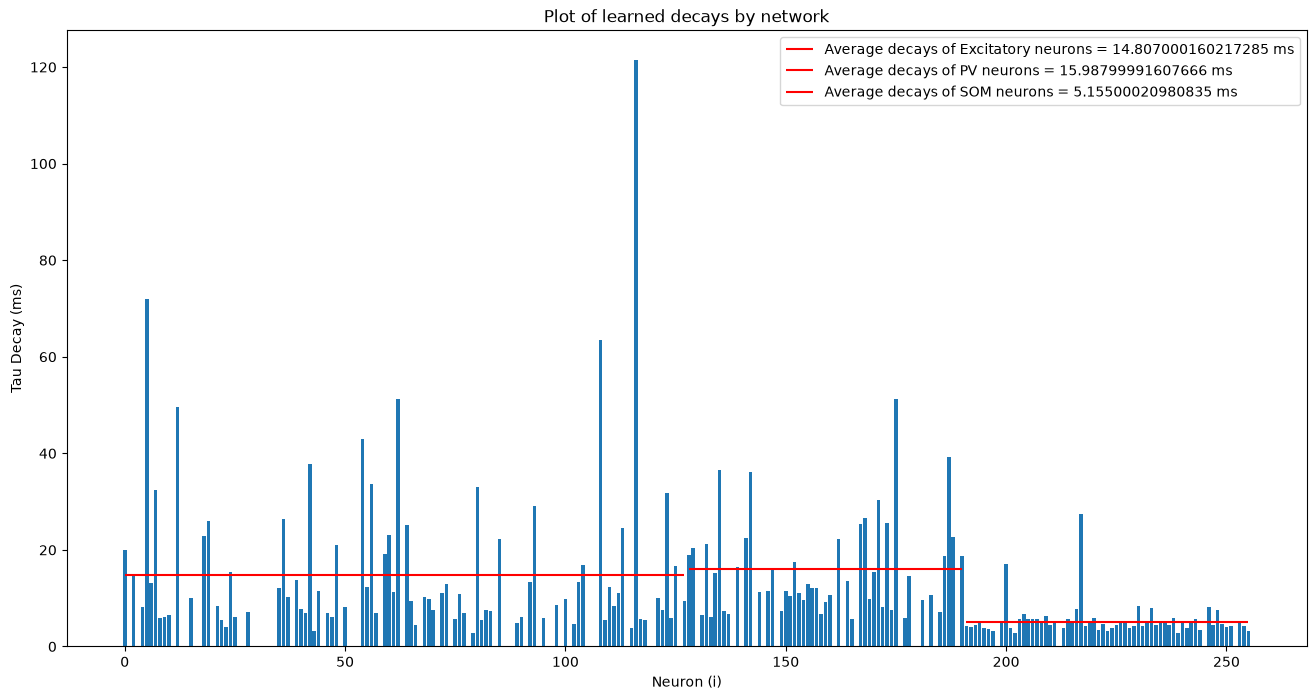

dict_keys(['weights_forward_0', 'weights_recurrent_0', 'weights_forward_1'])
dict_keys(['recurrent_mask_0'])
(256, 256)


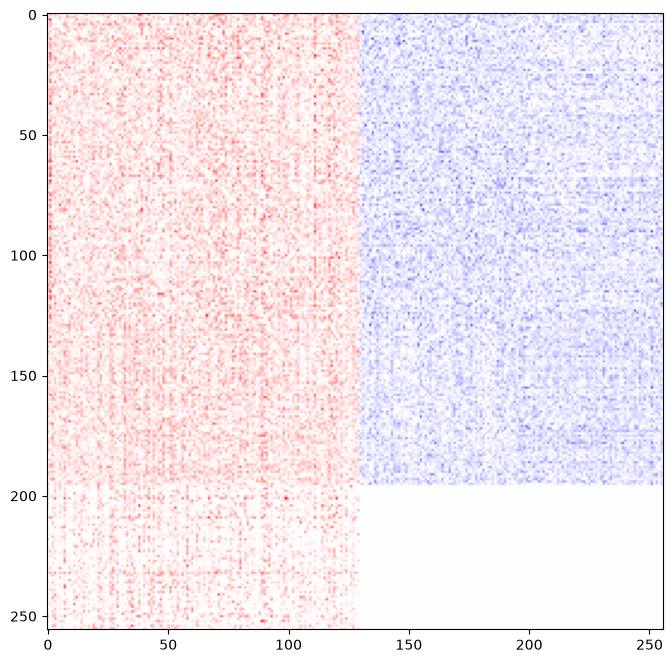

In [14]:
import matplotlib.pyplot as plt

dt = 0.001

def beta_to_tau(beta: np.ndarray, dt: float) -> np.ndarray:
    """
    Computes the inverse of 'beta = exp(-dt / tau)'.
    -dt / tau = log(beta)
    tau / -dt = 1/log(beta)
    tau = -dt/log(beta)
    """
    return -dt / np.log(beta)

seed = 4
beta = load_beta(seed=seed)
neurons = get_neurons(seed=seed)
neuron_ranges = get_neuron_ranges(neurons)
print(neuron_ranges)

taus = beta_to_tau(beta, dt) / dt

neuron_labels = list(neuron_ranges.keys())
per_neuron_averages = np.array([
    np.mean(beta[start: end]) for start, end in neuron_ranges.values()
])
per_neuron_averages = beta_to_tau(per_neuron_averages, dt) / dt

x_axis = np.arange(len(beta))
plt.figure(figsize=(16, 8))
plt.bar(x_axis, taus)
for i, (name, range) in enumerate(neuron_ranges.items()):
    y: np.array = per_neuron_averages[i]
    plt.hlines(y, *range, color="r", label=f"Average decays of {name} neurons = {y.round(3)} ms")
plt.xlabel("Neuron (i)")
plt.ylabel("Tau Decay (ms)")
plt.title("Plot of learned decays by network")
plt.legend()
plt.show()

# x_axis = np.arange(len(beta))
# plt.figure(figsize=(16, 8))
# plt.bar(neuron_labels, beta)
# plt.xlabel("Neuron (i)")
# plt.ylabel("Decay value")
# plt.title("Plot of learned decays by network")
# plt.show()

weights = get_data_seed("weights", seed=1)
print(weights.keys())
weight_masks = get_weight_masks(seed=1)
print(weight_masks.keys())
weights["weights_recurrent_0"] = weights["weights_recurrent_0"] * weight_masks["recurrent_mask_0"].T        # con_matrix is transposed in linears.py

w = weights["weights_recurrent_0"][-1]
print(w.shape)

plt.figure(figsize=(16, 8))
vmax = np.abs(w).max()
plt.imshow(w, cmap="bwr", vmin=-vmax, vmax=vmax)